# SWaT Dataset — Structure &amp; Data-Quality Deep Dive

This notebook walks through the SWaT dataset step by step: what it is, how it's shaped, and every data-quality issue to know about before building the PCA/windowed-PCA/CNN baselines (Phase A) or the TSFM+Forecast-Fallback pipeline (Phase B).

## What SWaT is

SWaT (Secure Water Treatment) is a scaled-down, physical water treatment testbed at iTrust (SUTD, Singapore) with **6 sequential process stages** (P1-P6: raw water intake, chemical dosing, ultrafiltration, de-chlorination, RO, RO permeate/backwash). Each stage has sensors (analog: flow/level/pressure/conductivity — `FIT/LIT/PIT/DPIT/AIT`) and actuators (discrete: pumps/motorized valves/UV — `P1xx.../MVxxx/UV401`), **51 points total**, logged at **1 Hz**.

Two files ship separately:
| File | Rows | Period | Content |
|---|---|---|---|
| `SWaT_Dataset_Normal_v1.xlsx` | 495,000 | 22/12/2015 16:30 → 28/12/2015 09:59:59 (~6 days) | Pure normal operation only — this is what you fit scalers/PCA/thresholds on |
| `SWaT_Dataset_Attack_v0.xlsx` | 449,919 | 28/12/2015 10:00:00 → 2/1/2016 14:59:59 (~6 days) | Normal interspersed with 35 attack segments — this is the test set |

Column layout in both files: `Timestamp`, then 51 sensor/actuator columns (`FIT101, LIT101, MV101, P101, ...`), then (Attack file only) a `Normal/Attack` label column.

## Why you can't just `pd.read_excel()` this

Two gotchas that will silently corrupt your data if you don't know about them going in — you'll verify both yourself in the cells below:
1. **openpyxl takes 10+ minutes** per file (they're 100-130MB workbooks) — we'll stream the raw worksheet XML instead, which takes ~40s.
2. **The two files don't have the same header shape.** You'll see this directly in Step 2.

Work through the cells in order — each one is a self-contained check for one issue, with a print statement telling you what to look for.

## Step 0 — Setup

Edit `SWAT_DIR` if your data lives somewhere else. Everything below only reads files — nothing here writes to the dataset.

In [5]:
import re
import time
import zipfile

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

SWAT_DIR = r"E:\UniversityOfArizona\Coursework\Capstone\$$SWAT Dataset A2-Dec 2015"
ATTACK_PATH = f"{SWAT_DIR}\\SWaT_Dataset_Attack_v0.xlsx"
NORMAL_PATH = f"{SWAT_DIR}\\SWaT_Dataset_Normal_v1.xlsx"

## Step 1 — Fast XLSX loader

`openpyxl` chokes on these workbooks (10+ min each). Instead we unzip the `.xlsx` (it's just a zip of XML files) and regex the raw cell XML out of `xl/worksheets/sheet1.xml` directly. This returns a list of `{column_letter: value}` dicts, one per row — note we have **not yet decided which row is the header**, that's the point of Step 2.

In [6]:
def fast_xlsx_rows(path: str, sheet_index: int = 0) -> list[dict]:
    """Stream raw worksheet XML out of the xlsx zip; return list of {col_letter: value} per row."""
    t0 = time.time()
    with zipfile.ZipFile(path) as z:
        shared = []
        if "xl/sharedStrings.xml" in z.namelist():
            ss_xml = z.read("xl/sharedStrings.xml").decode("utf-8", errors="replace")
            shared = re.findall(r"<t[^>]*>(.*?)</t>", ss_xml, re.S)
        xml = z.read(f"xl/worksheets/sheet{sheet_index+1}.xml").decode("utf-8", errors="replace")

    cell_pattern = re.compile(
        r'<c[^>]*r="([A-Z]+)\d+"[^>]*?(?: t="(\w+)")?>(?:<v>(.*?)</v>|<is><t[^>]*>(.*?)</t></is>)?</c>'
    )
    rows = []
    for row_xml in re.findall(r"<row[^>]*>(.*?)</row>", xml, re.S):
        row = {}
        for col_letter, ctype, val, inline_str in cell_pattern.findall(row_xml):
            if ctype == "s" and val != "":
                row[col_letter] = shared[int(val)] if val.isdigit() and int(val) < len(shared) else val
            else:
                row[col_letter] = inline_str if inline_str else val
        rows.append(row)
    print(f"parsed {len(rows)} raw rows in {time.time()-t0:.1f}s from {path.split(chr(92))[-1]}")
    return rows

## Step 2 — Load the Attack file, look at the header

Load the raw rows and print row 0 directly. **Check:** row 0 should already be the real per-sensor header (`Timestamp, FIT101, LIT101, ...`) — a single header row, nothing fancy. Keep this in mind for Step 8, where the Normal file will NOT look like this.

In [7]:
attack_raw = fast_xlsx_rows(ATTACK_PATH)
print("\nRow 0 (should be the real header):")
print(attack_raw[0])
print("\nRow 1 (first data row):")
print(attack_raw[1])

parsed 449920 raw rows in 37.1s from SWaT_Dataset_Attack_v0.xlsx

Row 0 (should be the real header):
{'A': ' Timestamp', 'B': 'FIT101', 'C': 'LIT101', 'D': ' MV101', 'E': 'P101', 'F': 'P102', 'G': ' AIT201', 'H': 'AIT202', 'I': 'AIT203', 'J': 'FIT201', 'K': ' MV201', 'L': ' P201', 'M': ' P202', 'N': 'P203', 'O': ' P204', 'P': 'P205', 'Q': 'P206', 'R': 'DPIT301', 'S': 'FIT301', 'T': 'LIT301', 'U': 'MV301', 'V': 'MV302', 'W': ' MV303', 'X': 'MV304', 'Y': 'P301', 'Z': 'P302', 'AA': 'AIT401', 'AB': 'AIT402', 'AC': 'FIT401', 'AD': 'LIT401', 'AE': 'P401', 'AF': 'P402', 'AG': 'P403', 'AH': 'P404', 'AI': 'UV401', 'AJ': 'AIT501', 'AK': 'AIT502', 'AL': 'AIT503', 'AM': 'AIT504', 'AN': 'FIT501', 'AO': 'FIT502', 'AP': 'FIT503', 'AQ': 'FIT504', 'AR': 'P501', 'AS': 'P502', 'AT': 'PIT501', 'AU': 'PIT502', 'AV': 'PIT503', 'AW': 'FIT601', 'AX': 'P601', 'AY': 'P602', 'AZ': 'P603', 'BA': 'Normal/Attack'}

Row 1 (first data row):
{'A': ' 28/12/2015 10:00:00 AM', 'B': '2.427057', 'C': '522.84670000000006', 

## Step 3 — Turn raw rows into a DataFrame

Build the column-letter -> name mapping from row 0, then drop that row and set it as the header.

In [8]:
def rows_to_df(raw_rows: list[dict], header_row_idx: int = 0) -> pd.DataFrame:
    all_letters = sorted({c for r in raw_rows for c in r.keys()}, key=lambda s: (len(s), s))
    df = pd.DataFrame(raw_rows, columns=all_letters)
    header = df.iloc[header_row_idx].tolist()
    df = df.iloc[header_row_idx + 1:].reset_index(drop=True)
    df.columns = header
    return df


swat_attack = rows_to_df(attack_raw, header_row_idx=0)
print("Shape:", swat_attack.shape)
print("Columns:", list(swat_attack.columns))

Shape: (449919, 53)
Columns: [' Timestamp', 'FIT101', 'LIT101', ' MV101', 'P101', 'P102', ' AIT201', 'AIT202', 'AIT203', 'FIT201', ' MV201', ' P201', ' P202', 'P203', ' P204', 'P205', 'P206', 'DPIT301', 'FIT301', 'LIT301', 'MV301', 'MV302', ' MV303', 'MV304', 'P301', 'P302', 'AIT401', 'AIT402', 'FIT401', 'LIT401', 'P401', 'P402', 'P403', 'P404', 'UV401', 'AIT501', 'AIT502', 'AIT503', 'AIT504', 'FIT501', 'FIT502', 'FIT503', 'FIT504', 'P501', 'P502', 'PIT501', 'PIT502', 'PIT503', 'FIT601', 'P601', 'P602', 'P603', 'Normal/Attack']


## Step 4 — The label column, and the `'A ttack'` typo

The last column is the label (`Normal` / `Attack`). **Check:** run `.value_counts()` and look closely — there's a third, near-identical value in there with an extra space. If you ever filter with `label == 'Attack'`, those rows get silently dropped. The fix is to match on substring (`'ttack' in label`) instead of exact equality.

In [9]:
label_col = swat_attack.columns[-1]
ts_col = swat_attack.columns[0]
print(f"Label column name: {label_col!r}")
print(swat_attack[label_col].value_counts())

# the correct way to flag attacks -- substring match, not exact equality
is_attack = swat_attack[label_col].astype(str).str.contains("ttack", case=False, na=False)
print(f"\nRows matched by exact == 'Attack':  {(swat_attack[label_col] == 'Attack').sum()}")
print(f"Rows matched by 'ttack' in label:    {is_attack.sum()}   <- use this one")
print(f"Difference (rows the naive filter silently drops): {is_attack.sum() - (swat_attack[label_col] == 'Attack').sum()}")

Label column name: 'Normal/Attack'
Normal/Attack
Normal     395298
Attack      54584
A ttack        37
Name: count, dtype: int64

Rows matched by exact == 'Attack':  54584
Rows matched by 'ttack' in label:    54621   <- use this one
Difference (rows the naive filter silently drops): 37


## Step 5 — Coerce sensor columns to numeric, check for bad values

All 51 sensor/actuator columns should coerce to numeric cleanly (no NaNs introduced). Confirm that.

In [10]:
sensor_cols = [c for c in swat_attack.columns if c not in (ts_col, label_col)]
print(f"# sensor/actuator columns: {len(sensor_cols)}")

numeric = swat_attack[sensor_cols].apply(pd.to_numeric, errors="coerce")
bad = numeric.isna().sum()
bad = bad[bad > 0]
print(f"Columns with NaN after numeric coercion: {len(bad)}  (should be 0)")
print(bad)

print(f"\nDuplicate full rows: {swat_attack.duplicated().sum()}  (should be 0)")
print(f"Duplicate timestamps: {swat_attack[ts_col].duplicated().sum()}  (should be 0)")

# sensor/actuator columns: 51
Columns with NaN after numeric coercion: 0  (should be 0)
Series([], dtype: int64)

Duplicate full rows: 0  (should be 0)
Duplicate timestamps: 0  (should be 0)


## Step 6 — Constant columns and discrete actuators vs. continuous sensors

`nunique()` per column splits the 51 points into three groups:
- **Constant** (1 unique value) — zero variance for this whole file; z-scoring these divides by zero std.
- **Low-cardinality (2-5 values)** — the discrete actuators (pumps/valves: `P1xx, MVxxx, UV401`), which take a small number of states, not continuous readings.
- **Everything else** — the continuous analog sensors (`FIT/LIT/PIT/DPIT/AIT`), which is what PCA reconstruction error should really be computed on.

**Check:** look at which specific columns land in each bucket — you'll want to decide explicitly whether PCA runs on all 51 or just the continuous subset.

In [11]:
nunique = numeric.nunique()

const_cols = sorted(nunique[nunique <= 1].index)
discrete_cols = sorted(nunique[(nunique > 1) & (nunique <= 5)].index)
continuous_cols = sorted(nunique[nunique > 5].index)

print(f"Constant columns ({len(const_cols)}): {const_cols}")
print(f"\nDiscrete actuator columns ({len(discrete_cols)}): {discrete_cols}")
print(f"\nContinuous sensor columns ({len(continuous_cols)}): {continuous_cols}")

print("\nValue ranges (continuous sensors), sorted by range span:")
desc = numeric[continuous_cols].describe().T[["min", "max", "mean", "std"]]
desc["range"] = desc["max"] - desc["min"]
print(desc.sort_values("range", ascending=False))

Constant columns (7): [' P202', 'P301', 'P401', 'P404', 'P502', 'P601', 'P603']

Discrete actuator columns (19): [' MV101', ' MV201', ' MV303', ' P201', ' P204', 'MV301', 'MV302', 'MV304', 'P101', 'P102', 'P203', 'P205', 'P206', 'P302', 'P402', 'P403', 'P501', 'P602', 'UV401']

Continuous sensor columns (25): [' AIT201', 'AIT202', 'AIT203', 'AIT401', 'AIT402', 'AIT501', 'AIT502', 'AIT503', 'AIT504', 'DPIT301', 'FIT101', 'FIT201', 'FIT301', 'FIT401', 'FIT501', 'FIT502', 'FIT503', 'FIT504', 'FIT601', 'LIT101', 'LIT301', 'LIT401', 'PIT501', 'PIT502', 'PIT503']

Value ranges (continuous sensors), sorted by range span:
                min          max        mean         std       range
LIT301   364.386300  1201.000000  910.076801   80.522063  836.613700
LIT401   243.014600  1002.781000  833.542913  186.068540  759.766400
LIT101   189.826300   925.032300  607.019967  125.303003  735.206000
AIT504     9.536016   442.463500   14.504030    7.944618  432.927484
PIT501     9.468726   254.341800 

## Step 7 — Attack segments: lengths, and the one segment that dominates everything

Group consecutive `is_attack` rows into segments (a new segment starts every time the label flips). **Check:** there should be 35 segments; look at the length distribution and specifically the longest one — it's a huge outlier.

In [ ]:
seg_id = (is_attack != is_attack.shift()).cumsum()
print(seg_id)
seg_stats = is_attack.groupby(seg_id).agg(["sum", "size"])
attack_segments = seg_stats[seg_stats["sum"] > 0].rename(columns={"size": "length_rows"})

print(f"# contiguous attack segments: {len(attack_segments)}")
print("\nLength (seconds, since 1 Hz) distribution:")
print(attack_segments["length_rows"].describe())

print("\nTop 5 longest segments:")
print(attack_segments["length_rows"].sort_values(ascending=False).head(5))

longest = attack_segments["length_rows"].idxmax()
pct_of_all_attack_time = attack_segments.loc[longest, "length_rows"] / is_attack.sum() * 100
print(f"\nLongest segment holds {pct_of_all_attack_time:.1f}% of ALL attack-labeled timesteps.")
print("-> any pointwise metric (plain F1, plain AUC) will be dominated by this one event.")
print("-> always also report segment-level / per-attack metrics, not just pointwise.")

0          1
1          1
2          1
3          1
4          1
          ..
449914    71
449915    71
449916    71
449917    71
449918    71
Name: Normal/Attack, Length: 449919, dtype: int64
# contiguous attack segments: 35

Length (seconds, since 1 Hz) distribution:
count       35.000000
mean      1560.600000
std       5985.260554
min        101.000000
25%        344.000000
50%        444.000000
75%        719.000000
max      35900.000000
Name: length_rows, dtype: float64

Top 5 longest segments:
Normal/Attack
44    35900
70     1690
42     1445
48     1171
14      964
Name: length_rows, dtype: int64

Longest segment holds 65.7% of ALL attack-labeled timesteps.
-> any pointwise metric (plain F1, plain AUC) will be dominated by this one event.
-> always also report segment-level / per-attack metrics, not just pointwise.


## Step 8 — Load the Normal file. Watch its header carefully.

This is the big one. Load the Normal file's raw rows and print rows 0, 1, and 2 — **don't skip straight to `rows_to_df`**. Compare what you see to Step 2's Attack-file header.

In [19]:
normal_raw = fast_xlsx_rows(NORMAL_PATH)
print("\nRow 0:", normal_raw[0])
print("\nRow 1:", normal_raw[1])
print("\nRow 2 (first real data row):", normal_raw[2])

parsed 495002 raw rows in 51.1s from SWaT_Dataset_Normal_v1.xlsx

Row 0: {'B': 'P1', 'G': 'P2', 'R': 'P3', 'AA': 'P4', 'AJ': 'P5', 'AW': 'P6'}

Row 1: {'A': ' Timestamp', 'B': 'FIT101', 'C': 'LIT101', 'D': 'MV101', 'E': 'P101', 'F': 'P102', 'G': 'AIT201', 'H': 'AIT202', 'I': 'AIT203', 'J': 'FIT201', 'K': 'MV201', 'L': 'P201', 'M': 'P202', 'N': 'P203', 'O': 'P204', 'P': 'P205', 'Q': 'P206', 'R': 'DPIT301', 'S': 'FIT301', 'T': 'LIT301', 'U': 'MV301', 'V': 'MV302', 'W': 'MV303', 'X': 'MV304', 'Y': 'P301', 'Z': 'P302', 'AA': 'AIT401', 'AB': 'AIT402', 'AC': 'FIT401', 'AD': 'LIT401', 'AE': 'P401', 'AF': 'P402', 'AG': 'P403', 'AH': 'P404', 'AI': 'UV401', 'AJ': 'AIT501', 'AK': 'AIT502', 'AL': 'AIT503', 'AM': 'AIT504', 'AN': 'FIT501', 'AO': 'FIT502', 'AP': 'FIT503', 'AQ': 'FIT504', 'AR': 'P501', 'AS': 'P502', 'AT': 'PIT501', 'AU': 'PIT502', 'AV': 'PIT503', 'AW': 'FIT601', 'AX': 'P601', 'AY': 'P602', 'AZ': 'P603', 'BA': 'Normal/Attack'}

Row 2 (first real data row): {'A': ' 22/12/2015 4:30:00 PM

**What you should see:** row 0 has only ~6 entries (`P1, P2, P3, P4, P5, P6` at a handful of column letters) — that's a *merged-cell process-stage group label* spanning each stage's columns, not a real header. Row 1 is the actual per-sensor header (`Timestamp, FIT101, LIT101, ...`), matching the Attack file's row 0. Row 2 is the first real data row.

So: Attack file → header at row 0, data from row 1. Normal file → header at row **1**, data from row **2**. If you call `rows_to_df(normal_raw, header_row_idx=0)` (the Attack-file convention) on this file, every column shifts by one and your "Timestamp" column becomes `P1`. Try it below and see for yourself, then load it correctly.

In [20]:
# WRONG -- demonstrates the trap
broken = rows_to_df(normal_raw, header_row_idx=0)
print("Wrong header_row_idx=0 gives columns:", list(broken.columns[:6]), "...")

# CORRECT
swat_normal = rows_to_df(normal_raw, header_row_idx=1)
print("\nCorrect header_row_idx=1 gives columns:", list(swat_normal.columns[:6]), "...")
print("Shape:", swat_normal.shape)
del broken

Wrong header_row_idx=0 gives columns: [nan, 'P1', nan, nan, nan, nan] ...

Correct header_row_idx=1 gives columns: [' Timestamp', 'FIT101', 'LIT101', 'MV101', 'P101', 'P102'] ...
Shape: (495000, 53)


## Step 9 — Cross-file column-name whitespace mismatch

Now that both files are loaded with correct headers, compare column name *sets* directly, then again after stripping whitespace. **Check:** the first comparison should show several "mismatched" columns that are actually the same sensor — just with an extra leading space in one file.

In [22]:
normal_cols_raw = set(swat_normal.columns)
attack_cols_raw = set(swat_attack.columns)

print("Raw (unstripped) mismatch:")
print("  In normal, not in attack:", normal_cols_raw - attack_cols_raw)
print("  In attack, not in normal:", attack_cols_raw - normal_cols_raw)

normal_cols_stripped = {c.strip() for c in normal_cols_raw}
attack_cols_stripped = {c.strip() for c in attack_cols_raw}
print("\nAfter .strip() on both sides:")
print("  Still mismatched:", normal_cols_stripped ^ attack_cols_stripped)
print("  (empty set means they now line up exactly)")

# always strip column names right after loading, before any join/merge/comparison
swat_normal.columns = [c.strip() for c in swat_normal.columns]
swat_attack.columns = [c.strip() for c in swat_attack.columns]

Raw (unstripped) mismatch:
  In normal, not in attack: set()
  In attack, not in normal: set()

After .strip() on both sides:
  Still mismatched: set()
  (empty set means they now line up exactly)


## Step 10 — Constant-column sets differ between Normal and Attack files

Recompute "constant columns" on the Normal file, and compare to the Attack-file constant set from Step 6. **Check:** some columns are constant in one file but not the other — those are the ones to think carefully about before blindly dropping "zero-variance" columns fit on the (benign-only) Normal file.

In [23]:
# recompute label/ts/sensor cols now that names are stripped (Step 9 changed them in place)
label_col = "Normal/Attack"
ts_col = "Timestamp"
sensor_cols = [c for c in swat_attack.columns if c not in (ts_col, label_col)]

normal_numeric = swat_normal[sensor_cols].apply(pd.to_numeric, errors="coerce")
normal_nunique = normal_numeric.nunique()
normal_const_cols = sorted(normal_nunique[normal_nunique <= 1].index)

print(f"Constant in NORMAL file ({len(normal_const_cols)}): {normal_const_cols}")
print(f"Constant in ATTACK file ({len(const_cols)}): {const_cols}")

only_in_normal = sorted(set(normal_const_cols) - set(const_cols))
only_in_attack = sorted(set(const_cols) - set(normal_const_cols))
print(f"\nConstant in Normal but VARIES during Attack (would lose signal if dropped pre-attack): {only_in_normal}")
print(f"Constant in Attack but varies in Normal (less concerning, just an idle actuator in training): {only_in_attack}")

Constant in NORMAL file (11): ['P102', 'P201', 'P202', 'P204', 'P206', 'P401', 'P403', 'P404', 'P502', 'P601', 'P603']
Constant in ATTACK file (7): [' P202', 'P301', 'P401', 'P404', 'P502', 'P601', 'P603']

Constant in Normal but VARIES during Attack (would lose signal if dropped pre-attack): ['P102', 'P201', 'P202', 'P204', 'P206', 'P403']
Constant in Attack but varies in Normal (less concerning, just an idle actuator in training): [' P202', 'P301']


## Step 11 — Startup transient at the beginning of the Normal file

Compare a volatile tank-level sensor's mean/std in the first hour (3600 rows, 1 Hz) vs. the rest of the file. **Check:** the first hour should look visibly different (plant still filling/stabilizing) — if you fit PCA/scalers on the full Normal file including this transient, you're letting an artificial startup period skew what "normal" means. Try a couple of other continuous sensors too (`LIT301`, `LIT401`, `AIT201`) to see how long the transient actually lasts — don't assume exactly 1 hour.

LIT101   first-hour mean/std =   239.26/  58.86   rest mean/std =   590.08/ 118.28
LIT301   first-hour mean/std =   279.76/ 100.38   rest mean/std =   904.44/  77.28
LIT401   first-hour mean/std =   263.85/ 106.21   rest mean/std =   887.37/  69.77
AIT201   first-hour mean/std =   261.76/   5.68   rest mean/std =   263.80/   4.78


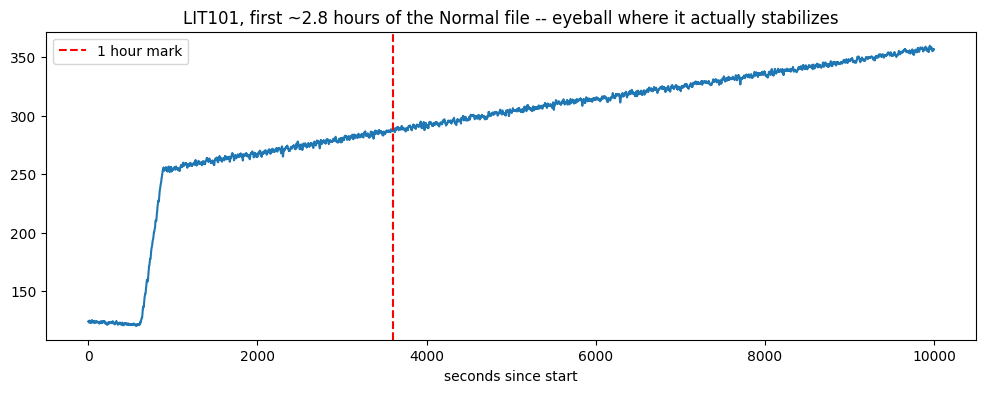

In [24]:
import matplotlib.pyplot as plt

for col in ["LIT101", "LIT301", "LIT401", "AIT201"]:
    series = normal_numeric[col]
    first_hour, rest = series.iloc[:3600], series.iloc[3600:]
    print(f"{col:8s} first-hour mean/std = {first_hour.mean():8.2f}/{first_hour.std():7.2f}   "
          f"rest mean/std = {rest.mean():8.2f}/{rest.std():7.2f}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(normal_numeric["LIT101"].iloc[:10000].values)
ax.axvline(3600, color="red", linestyle="--", label="1 hour mark")
ax.set_title("LIT101, first ~2.8 hours of the Normal file -- eyeball where it actually stabilizes")
ax.set_xlabel("seconds since start")
ax.legend()
plt.show()

## Step 12 — The attack metadata CSV, and its trailing junk rows

`List_of_attacks_Final(Sheet1).csv` documents the 41 real attacks (`Attack #` 1-41) with start/end time, attack point, and expected impact. **Check:** load it naively and look at `.shape` — you'll get more than 41 rows. Print the tail: there are extra rows after attack 41 that are NOT attacks — blank padding rows, then a 4-line "taxonomy legend" (`Single Stage Single Point Attacks`, etc. — just category *names*, not tied to any specific attack number via a column), then a free-text footnote about attack #26's behavior. Filter on `Attack #` not being NaN before using this file, and don't assume the taxonomy legend gives you a ready-made per-attack label — it doesn't; you'd need the original SWaT paper's attack table for that per-attack mapping.

In [25]:
attacks_meta_raw = pd.read_csv(f"{SWAT_DIR}\\List_of_attacks_Final(Sheet1).csv")
print("Raw shape (includes junk tail rows):", attacks_meta_raw.shape)
print("\nTail rows -- notice these are NOT attacks:")
print(attacks_meta_raw.tail(8).to_string())

# keep only real attack rows
attacks_meta = attacks_meta_raw[attacks_meta_raw["Attack #"].notna()].copy()
print(f"\nReal attack rows after filtering: {len(attacks_meta)}  (should be 41)")

# "No Physical Impact" attacks are flagged as a VALUE inside 'Attack Point'
# (e.g. "No Physical Impact Attack"), not a separate boolean column.
no_impact_mask = attacks_meta["Attack Point"].astype(str).str.contains("No Physical Impact", case=False, na=False)
print(f"'No Physical Impact' attacks: {no_impact_mask.sum()} / {len(attacks_meta)}")
print(attacks_meta.loc[no_impact_mask, ["Attack #", "Attack Point"]])

Raw shape (includes junk tail rows): (49, 9)

Tail rows -- notice these are NOT attacks:
                                                                                                                                                                                                                                                                       Attack #                         Start Time End Time Attack Point Start State Attack Actual Change Expected Impact or attacker intent Unexpected Outcome
41                                                                                                                                                                                                                                                                          NaN                                NaN      NaN          NaN         NaN    NaN           NaN                                NaN                NaN
42                                                                             

## Summary — what you should have confirmed yourself by now

1. SWaT = 6-stage water treatment testbed, 51 points (continuous sensors + discrete actuators), 1 Hz, Normal file (benign-only, fit scalers/thresholds here) + Attack file (test set, 35 attack segments).
2. The three label values and the `'A ttack'` typo — substring match, not `==`.
3. 51 sensor columns coerce cleanly to numeric; no NaNs, no duplicate rows/timestamps in the Attack file.
4. 7 constant + 19 discrete-actuator + 25 continuous-sensor columns in the Attack file — decide explicitly how PCA/CNN treat the discrete ones.
5. 35 attack segments, one of which (~10h) holds 66% of all attack-labeled time — report segment-level metrics alongside pointwise ones.
6. **The Normal file has a different header shape than the Attack file** (merged 2-row group header vs. single-row) — load them differently or you silently corrupt the Normal file's columns.
7. **7 column names differ by leading whitespace** between the two files — strip before any comparison/merge.
8. **Constant-column sets differ between files** — some columns idle in training but active during attacks; dropping "zero-variance" columns based on Normal-file stats alone can throw away real attack signal.
9. **A startup transient** in the first part of the Normal file — decide a settling-period cutoff before fitting anything on it.
10. The attack metadata CSV has **41 real attack rows plus 8 trailing junk rows** (blank padding + a taxonomy legend that is NOT a per-attack column + a footnote) — filter on `Attack #` not NaN. The 4 taxonomy category names (Single/Multi Stage x Single/Multi Point) are only named as a disconnected legend here, not mapped to individual attacks — for a real per-attack category label you'd need the original SWaT paper's attack table, not this CSV alone.

Next: once you're comfortable with these, the same kind of pass needs to happen on WADI (different issues: a 264K-row gap, 4 fully-dead columns, inverted labels, a junk header line in the attack CSV, Excel-mangled timestamps) — happy to build that notebook the same way when you're ready.